# Adenylate kinase: transition paths from four protocols

Three paths each from DIMS, FRODA, and restrained targeted MD at a fast (rTMD-F) and a slow (rTMD-S) pulling
rate (MDAnalysis PSAnalysisTutorial). FDM on the backbone coordinates: L² distance, σ = median, α = 0. The
collective variables are computed for comparison only.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # repository root (notebook lives in systems/<name>/)
sys.path[:0] = [str(ROOT), str(Path.cwd())]
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathfdm import embed
from pathfdm.features import feature_matrix
from pathfdm.surrogate import fit_surrogate
from pathfdm.evaluation import auc_per_coordinate, kmeans_ari, align_signs, compare_embeddings
from pathfdm.plotting import apply_style, plot_space, plot_parity, plot_beeswarm
import load_data as D
apply_style()
N_JOBS = 8
from sklearn.decomposition import PCA

In [2]:
ts, labels, cvs = D.load()
print(ts.names)

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


12 paths | 855 backbone atoms | 92-142 frames
['rTMD-F_1', 'rTMD-F_2', 'rTMD-F_3', 'rTMD-S_1', 'rTMD-S_2', 'rTMD-S_3', 'DIMS_1', 'DIMS_2', 'DIMS_3', 'FRODA_1', 'FRODA_2', 'FRODA_3']


## Collective-variable projections

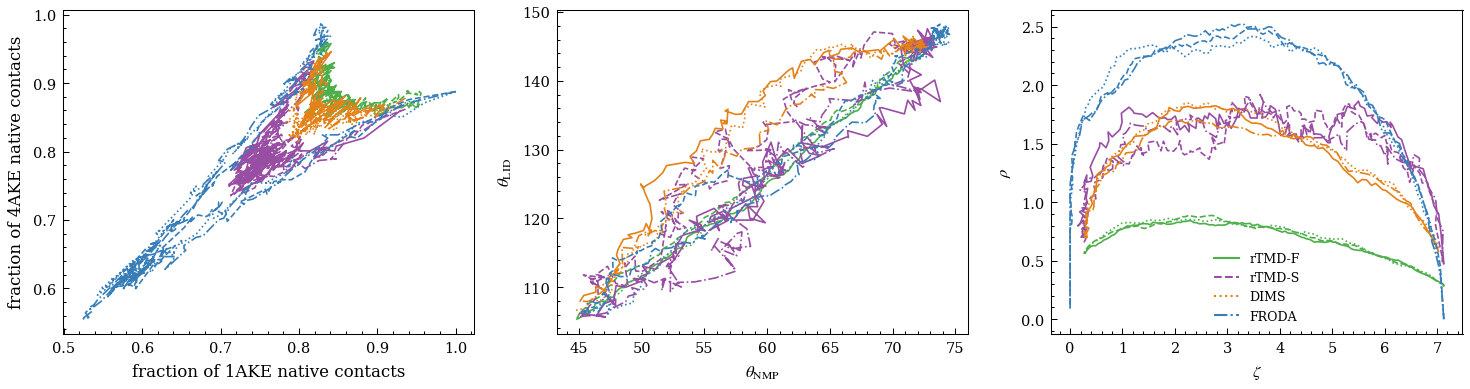

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8))
for c, m in zip(cvs, labels):
    col = D.LABEL_CONFIG[m]["color"]
    axs[0].plot(c[:, 0], c[:, 1], color=col, lw=0.8); axs[1].plot(c[:, 2], c[:, 3], color=col, lw=0.8)
    axs[2].plot(c[:, 4], c[:, 5], color=col, lw=0.8)
for ax, (i, j) in zip(axs, [(0, 1), (2, 3), (4, 5)]):
    ax.set_xlabel(f"${D.CV_NAMES[i]}$"); ax.set_ylabel(f"${D.CV_NAMES[j]}$")
axs[0].set_xlabel("fraction of 1AKE native contacts"); axs[0].set_ylabel("fraction of 4AKE native contacts")
for k, cfg in D.LABEL_CONFIG.items():
    axs[2].plot([], [], color=cfg["color"], label=cfg["name"])
axs[2].legend(fontsize=6); plt.tight_layout(); plt.show()

## PCA of the backbone coordinates vs FDM

PCA explained variance: [0.765 0.063]


sigma = 52.41


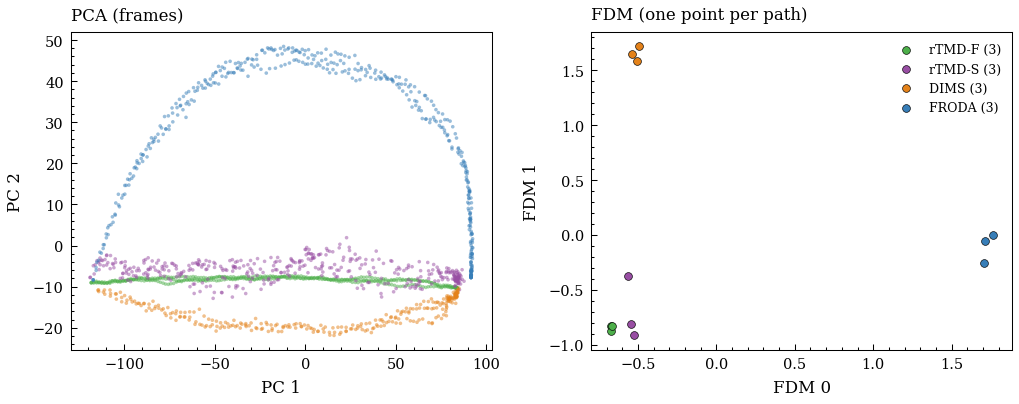

,method,FDM 0,FDM 1,sd FDM 1
0,rTMD-F,-0.67,-0.84,0.02
1,rTMD-S,-0.54,-0.70,0.23
2,DIMS,-0.51,1.65,0.05
3,FRODA,1.73,-0.10,0.11


In [4]:
pca = PCA(2).fit(np.vstack(ts.coords))
print("PCA explained variance:", np.round(pca.explained_variance_ratio_, 3))
Z, model = embed(ts.fd, metric="l2", return_model=True)
print(f"sigma = {model.sigma_:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(7, 2.9))
for c, m in zip(ts.coords, labels):
    p = pca.transform(c); axs[0].scatter(p[:, 0], p[:, 1], s=3, color=D.LABEL_CONFIG[m]["color"], alpha=0.5, edgecolors="none")
axs[0].set_xlabel("PC 1"); axs[0].set_ylabel("PC 2"); axs[0].set_title("PCA (frames)")
plot_space(Z, labels, D.LABEL_CONFIG, ax=axs[1], title="FDM (one point per path)")
plt.tight_layout(); plt.show()
pd.DataFrame([{"method": D.METHODS[k], "FDM 0": Z[labels == k, 0].mean(), "FDM 1": Z[labels == k, 1].mean(),
               "sd FDM 1": Z[labels == k, 1].std()} for k in range(4)]).round(2)